In [ ]:
import numpy as np
import os
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES','0')
import torch

from alphagenome.data import genome
from alphagenome.models import dna_client
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.interpretation import ism
from alphagenome.models import dna_client
from alphagenome.models import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd
from tangermeme.ersatz import dinucleotide_shuffle
from tangermeme.utils import one_hot_encode, characters, random_one_hot
from tangermeme.marginalize import marginalize
from tangermeme.ersatz import substitute
import random
from tqdm import tqdm
import time
from alphagenome.data import gene_annotation, genome, track_data, transcript
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components
from tangermeme.io import extract_loci
from tqdm.auto import tqdm
from tangermeme.ablate import ablate
from tangermeme.ersatz import dinucleotide_shuffle
import seaborn; seaborn.set_style('whitegrid')
import grelu.resources
from utils import create_marginalization_sequence, ablate_motifs, marginalize_motifs, annotate_with_peak_distances
from grelu.visualize import plot_ISM
from grelu.interpret import score
from grelu.interpret import score
from grelu.transforms.prediction_transforms import Aggregate



/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.27.2 is exactly one major version older than the runtime version 6.31.1 at alphagenome/protos/dna_model.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.27.2 is exactly one major version older than the runtime version 6.31.1 at alphagenome/protos/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm a

In [2]:
grelu.resources.projects()

wandb: Currently logged in as: kobbad (kamalobbad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


['tutorial-2',
 'decima',
 'human-mpra-gosai-2024',
 'GM12878_dnase',
 'demo',
 'human-mpra-agrawal-2023',
 'binary_atac_cell_lines',
 'model-zoo-test',
 'alzheimers-variant-tutorial',
 'microglia-scatac-tutorial',
 'human-chromhmm-fullstack',
 'human-atac-catlas',
 'borzoi',
 'yeast-gpra',
 'enformer']

In [3]:
grelu.resources.artifacts("borzoi", type_is="model")


['human_fold3',
 'human_fold2',
 'human_fold1',
 'human_fold0',
 'mouse_rep3',
 'mouse_rep2',
 'mouse_rep1',
 'mouse_rep0',
 'human_rep3',
 'human_rep2',
 'human_rep1',
 'human_rep0']

In [4]:
model = grelu.resources.load_model(
    project="borzoi",
    model_name="human_fold0",
)


wandb: Downloading large artifact human_fold0:latest, 711.00MB. 1 files... 
wandb:   1 of 1 files downloaded.  
Done. 0:0:31.3 (22.7MB/s)


In [5]:
model.data_params.keys()

dict_keys(['tasks', 'train_seq_len', 'train_label_len', 'train_genome', 'train_bin_size'])

In [13]:
seq_len = model.data_params['train_seq_len']

In [7]:
tasks = pd.DataFrame(model.data_params['tasks'])
tasks.shape

(7611, 10)

In [8]:
hit_path = "/users/kobbad/feat_leakage/all_ap1_motifs/OCTSOX_FIMO_HITS/fimo.tsv"
motif_hits = pd.read_csv(hit_path, sep='\t').dropna()

In [25]:
motif_hits = motif_hits[motif_hits.sequence_name.apply(lambda x: len(x) < 5)]

In [26]:
first_quantile = motif_hits.score.quantile(0.25).item()
second_quantile = motif_hits.score.quantile(0.5).item()
third_quantile = motif_hits.score.quantile(0.75).item()

motif_list_first = np.unique(motif_hits[motif_hits.score <= first_quantile].matched_sequence.values)
motif_list_second = np.unique(motif_hits[(motif_hits.score > first_quantile) & (motif_hits.score <= second_quantile)].matched_sequence.values)
motif_list_third = np.unique(motif_hits[(motif_hits.score > second_quantile) & (motif_hits.score <= third_quantile)].matched_sequence.values)
motif_list_fourth = np.unique(motif_hits[motif_hits.score > third_quantile].matched_sequence.values)

In [54]:
motif_df = motif_hits[motif_hits.score > third_quantile]
preds_with_motif, preds_with_ablated_motif, hits_sampled = ablate_motifs(motif_df, model, motif_length = 14, num_loci = 500, seq_len = seq_len)

Loading Loci: 100%|██████████| 500/500 [00:01<00:00, 439.61it/s]
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: UserWarning: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-

Predicting DataLoader 0: 100%|██████████| 41/41 [02:03<00:00,  0.33it/s]


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]


Predicting DataLoader 0: 100%|██████████| 41/41 [02:06<00:00,  0.33it/s]


In [61]:
dnase_tasks = tasks[tasks.assay == "DNASE"]
dnase_idxs = dnase_tasks.index.to_numpy()

In [69]:
preds_motif_dnase = preds_with_motif[:,dnase_idxs,:]
preds_ablated_motif_dnase = preds_with_ablated_motif[:,dnase_idxs,:]

scores = preds_motif_dnase - preds_ablated_motif_dnase
scores.shape

(488, 674, 6144)

In [75]:
top_idxs = np.argsort(scores.sum(axis=2).mean(axis=0))

In [76]:
dnase_tasks.iloc[top_idxs[:10]]

,name,file,clip,clip_soft,scale,sum_stat,strand_pair,description,assay,sample
1434,ENCFF369NZI,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1434,DNASE:WERI-Rb-1,DNASE,WERI-Rb-1
1355,ENCFF102UQK,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1355,DNASE:amniotic epithelial cell,DNASE,amniotic epithelial cell
1391,ENCFF634YGE,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1391,DNASE:retinal pigment epithelial cell,DNASE,retinal pigment epithelial cell
1329,ENCFF869ECL,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1329,DNASE:fibroblast of the aortic adventitia female,DNASE,fibroblast of the aortic adventitia female
1334,ENCFF747REW,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1334,DNASE:stromal cell of bone marrow male,DNASE,stromal cell of bone marrow male
1340,ENCFF171BUA,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1340,DNASE:GM04503,DNASE,GM04503
1699,ENCFF622CII,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1699,DNASE:umbilical cord embryo (59 days) and male...,DNASE,umbilical cord embryo (59 days) and male embry...
1395,ENCFF652HJH,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1395,DNASE:fibroblast of villous mesenchyme,DNASE,fibroblast of villous mesenchyme
1877,ENCFF443KCU,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1877,DNASE:large intestine male embryo (108 days),DNASE,large intestine male embryo (108 days)
1411,ENCFF302JEV,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1411,DNASE:fibroblast of dermis female adult,DNASE,fibroblast of dermis female adult


In [77]:
fibroblast_bed_file = "/users/kobbad/feat_leakage/enformer_v2/ENCFF184KAM.bed.gz"
motif_hits = "/users/kobbad/feat_leakage/all_ap1_motifs/OCTSOX_FIMO_HITS/fimo.tsv"
hits_with_distance = annotate_with_peak_distances(motif_hits, fibroblast_bed_file)

/users/kobbad/feat_leakage/borzoi_v2/utils.py:117: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/users/kobbad/feat_leakage/borzoi_v2/utils.py:118: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/users/kobbad/feat_leakage/borzoi_v2/utils.py:119: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
100%|██████████| 64256/64256 [00:02<00:0

In [80]:
hits = hits_with_distance[hits_with_distance.distance < 5000]

In [83]:
first_quantile = hits.score.quantile(0.25).item()
second_quantile = hits.score.quantile(0.5).item()
third_quantile = hits.score.quantile(0.75).item()

hits_df = hits[hits.score > third_quantile]
preds_with_motif, preds_with_ablated_motif, hits_sampled = ablate_motifs(hits_df, model, motif_length = 14, num_loci = 500, seq_len = seq_len)

Loading Loci: 100%|██████████| 500/500 [00:01<00:00, 379.12it/s]
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: PossibleUserWarning: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Predicting DataLoader 0: 100%|██████████| 42/42 [02:07<00:00,  0.33it/s]


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]


Predicting DataLoader 0: 100%|██████████| 42/42 [02:15<00:00,  0.31it/s]


In [85]:
preds_with_motif.shape, tasks.shape

((494, 7611, 6144), (7611, 10))

In [86]:
dnase_idxs

array([1276, 1277, 1278, 1279, 1280, 1281, 1282, 1283, 1284, 1285, 1286,
       1287, 1288, 1289, 1290, 1291, 1292, 1293, 1294, 1295, 1296, 1297,
       1298, 1299, 1300, 1301, 1302, 1303, 1304, 1305, 1306, 1307, 1308,
       1309, 1310, 1311, 1312, 1313, 1314, 1315, 1316, 1317, 1318, 1319,
       1320, 1321, 1322, 1323, 1324, 1325, 1326, 1327, 1328, 1329, 1330,
       1331, 1332, 1333, 1334, 1335, 1336, 1337, 1338, 1339, 1340, 1341,
       1342, 1343, 1344, 1345, 1346, 1347, 1348, 1349, 1350, 1351, 1352,
       1353, 1354, 1355, 1356, 1357, 1358, 1359, 1360, 1361, 1362, 1363,
       1364, 1365, 1366, 1367, 1368, 1369, 1370, 1371, 1372, 1373, 1374,
       1375, 1376, 1377, 1378, 1379, 1380, 1381, 1382, 1383, 1384, 1385,
       1386, 1387, 1388, 1389, 1390, 1391, 1392, 1393, 1394, 1395, 1396,
       1397, 1398, 1399, 1400, 1401, 1402, 1403, 1404, 1405, 1406, 1407,
       1408, 1409, 1410, 1411, 1412, 1413, 1414, 1415, 1416, 1417, 1418,
       1419, 1420, 1421, 1422, 1423, 1424, 1425, 14

In [87]:
dnase_tasks = tasks[tasks.assay == "DNASE"]
dnase_idxs = dnase_tasks.index.to_numpy()

preds_motif_dnase = preds_with_motif[:,dnase_idxs,:]
preds_ablated_motif_dnase = preds_with_ablated_motif[:,dnase_idxs,:]

scores = preds_motif_dnase - preds_ablated_motif_dnase
scores.shape

(494, 674, 6144)

In [ ]:
# 135 is the DNase task for the fibroblast #ENCFF302JEV
scores.sum(axis=2).mean(axis=0)[135]

np.float32(-0.0862381)

In [104]:
dnase_tasks.name.to_list().index("ENCFF302JEV")

135

In [124]:
dnase_tasks[dnase_tasks.name == "ENCFF302JEV"]

,name,file,clip,clip_soft,scale,sum_stat,strand_pair,description,assay,sample
1411,ENCFF302JEV,/home/drk/tillage/datasets/human/dnase/encode/...,128,32,2.0,mean,1411,DNASE:fibroblast of dermis female adult,DNASE,fibroblast of dermis female adult


In [111]:
np.argsort(scores[:, 135, :].sum(axis=1))[:10]

array([ 98, 230, 493, 312, 371,  40, 246, 238, 180, 320])

In [118]:
chrom, start, end = hits_sampled.iloc[98]
fasta = "/oak/stanford/groups/akundaje/jmschr/common/hg38/hg38.fa"
seq = extract_loci(pd.DataFrame({'chromosome':[chrom], 'start':[start], 'end':[end]}), fasta, in_window = seq_len, verbose=True).squeeze()
seq_str = characters(seq)

Loading Loci: 100%|██████████| 1/1 [00:00<00:00,  3.73it/s]


In [ ]:
seq_idx_list = np.argsort(scores[:, 135, :].sum(axis=1))[:50]

ism_scores = []

for s in seq_idx_list:
    chrom, start, end = hits_sampled.iloc[s]
    fasta = "/oak/stanford/groups/akundaje/jmschr/common/hg38/hg38.fa"
    seq = extract_loci(pd.DataFrame({'chromosome':[chrom], 'start':[start], 'end':[end]}), fasta, in_window = seq_len, verbose=True).squeeze()
    seq_str = characters(seq)
    
    SEQ_LEN = seq_len
    predict_transform = Aggregate([1411], length_aggfunc = 'sum', model=model)

    start_pos = SEQ_LEN // 2 - 50
    end_pos = SEQ_LEN // 2 + 50
    compare_func = "log2FC"
    devices = 0
    batch_size = 12
    return_df = True

    ism_score = score.ISM_predict(
        seqs = seq_str,
        model = model,
        prediction_transform = predict_transform,
        devices = devices,
        batch_size = batch_size,
        num_workers = 1, 
        start_pos = start_pos,
        end_pos = end_pos,
        compare_func = compare_func,
        return_df = return_df,
    )

    ism_scores.append(ism_score)

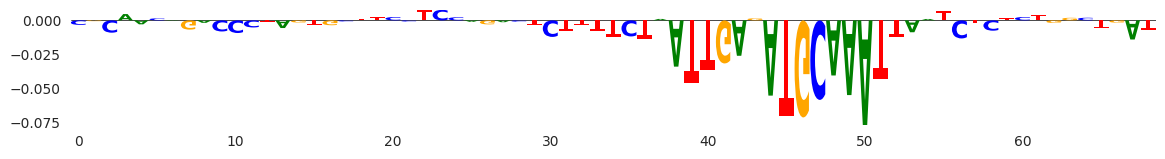

In [131]:
import seaborn as sns
sns.set_style('white') 
plot_ISM(ism_scores[1], method="logo", start_pos = 5, end_pos = 75,figsize=(14, 1.5))
# Save as PDF
plt.savefig('ism_plot.pdf', format='pdf', bbox_inches='tight', dpi=300)

# Save as SVG
plt.savefig('ism_plot.svg', format='svg', bbox_inches='tight')

# Display the plot
plt.show()

In [134]:
chrom, start, end = hits_sampled.iloc[230]

f"{chrom}:{start}-{end}"

'chr20:20464157-20464169'

In [138]:
out_window = scores.shape[2]

In [139]:
bigwig_path = "/users/kobbad/feat_leakage/enformer_v2/ENCFF361BTT.bigWig"

locus = pd.DataFrame({'chrom':[chrom], 'start':[start], 'end':[end]})

locus, signal = extract_loci(locus, fasta, [bigwig_path],out_window=out_window * 32, in_window = SEQ_LEN, verbose=True)

locus.shape, signal.shape

Loading Loci: 100%|██████████| 1/1 [00:00<00:00, 12.23it/s]


(torch.Size([1, 4, 524288]), torch.Size([1, 1, 196608]))

In [ ]:
scores[230, 135, :]

(6144,)

In [146]:
_, actual_profile = extract_loci(pd.DataFrame({"chrom": [chrom], 
                                            "start": [start], 
                                            "end":[end]}, 
                                           index=None), 
                                           fasta, 
                                           signals=[bigwig_path],
                                           in_window = SEQ_LEN, 
                                           out_window=out_window * 32, 
                                           verbose=True)
actual_values = actual_profile.squeeze().numpy()[:,np.newaxis]
actual_metadata = pd.DataFrame({"name": ["actual"], "strand": ["+"]})

interval = genome.Interval(chrom, start, end).resize(out_window * 32)

actual_track_data = track_data.TrackData(actual_values,
                                         actual_metadata,
                                         interval = interval)


expanded_prediction = np.repeat(preds_motif_dnase[230, 135, :], 32).squeeze()[:,np.newaxis]
predicted_metadata = pd.DataFrame({"name": ["predicted"], "strand": ["+"]})
predicted_track_data = track_data.TrackData(expanded_prediction,
                                            predicted_metadata,
                                            interval = interval)

Loading Loci: 100%|██████████| 1/1 [00:00<00:00, 83.73it/s]

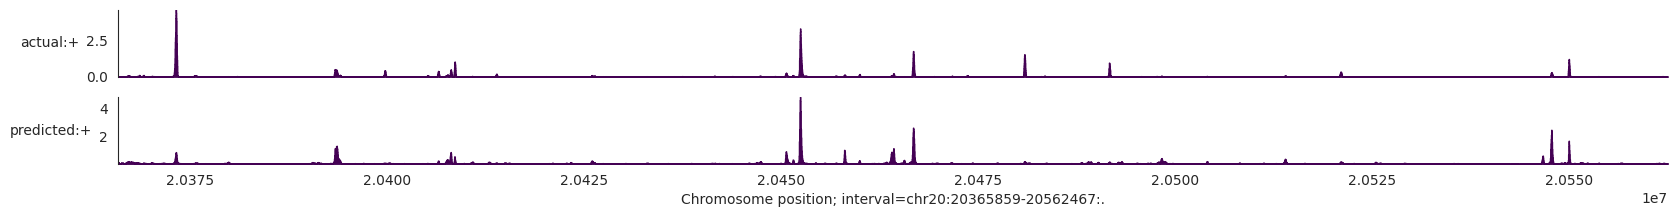

In [147]:
import seaborn as sns
sns.set_style("white")  
plot_components.plot(
    components=[
        plot_components.Tracks(actual_track_data, filled=True),
        plot_components.Tracks(predicted_track_data, filled=True),
    ],
    interval=interval,
)
# Save as SVG and PDF
plt.savefig('profile_plot.svg', format='svg', bbox_inches='tight')
plt.savefig('profile_plot.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [145]:
preds_motif_dnase.shape

(494, 674, 6144)